# 03 · Experimentos: tres familias con HPO

**Propósito.** Documentar el modelado del pronóstico diario de vistas del canal MLB: datos de entrada, *features*, *target*, preprocesamiento, particiones, métrica, búsqueda de hiperparámetros (HPO) con Optuna para tres familias distintas y comparación de sus mejores modelos.

El entrenamiento real lo ejecuta el flow de Prefect (`src/entrenamiento/flow.py`, ver [05-pipeline](05-pipeline.ipynb)); este notebook **no reentrena**: reconstruye los datos con las mismas funciones de `src/entrenamiento/` y lee los runs registrados en MLflow para analizarlos.

| Elemento | Decisión |
|---|---|
| Unidad de observación | Un día calendario del canal oficial de la MLB |
| Target | `target_views`: vistas acumuladas de los videos publicados en el día *t* |
| Features | `lag_14 … lag_1`: el target de los 14 días previos (`t-14 … t-1`) |
| Preprocesamiento | `StandardScaler` dentro del `Pipeline`, ajustado solo con datos de entrenamiento |
| Particiones | Temporales sin mezcla: 70 % train · 15 % validación (HPO) · 15 % test (evaluación final) |
| Métrica principal | RMSE en validación (**se minimiza**); MAE y MAPE como complementarias |
| Familias | `ridge` (lineal regularizado), `random-forest` (bagging de árboles), `gradient-boosting` (boosting de árboles por histogramas) |
| HPO | Optuna `TPESampler(seed=42)`, 20 trials por familia, mismo split para todas |

In [1]:
import os, sys, json
from pathlib import Path

# Los notebooks se ejecutan desde la raíz del repositorio para compartir rutas con src/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
from src.entrenamiento.reportes import configurar_mlflow
cfg = configurar_mlflow()
print("Tracking URI :", cfg["tracking_uri"])
print("Registry URI :", cfg["registry_uri"])
print("Experimento  :", cfg["experimento"])
print("Modelo       :", cfg["modelo"], "@" + cfg["alias"])

Tracking URI : sqlite:///mlflow.db
Registry URI : sqlite:///mlflow.db
Experimento  : /Shared/pcd-otono-2026-proyecto-tubecast
Modelo       : workspace.default.pcd_otono_2026_tubecast @champion


## 1. Datos y serie diaria

`descargar_datos_mlb()` lee `data/raw/mlb_raw_videos.parquet` (o lo descarga de la YouTube Data API v3 si no existe; ver [data/README.md](../data/README.md)). `construir_serie_diaria()` agrupa por fecha de publicación, suma las vistas y rellena con 0 los días sin publicaciones.

In [3]:
from src.entrenamiento.datos import (
    descargar_datos_mlb, construir_serie_diaria, crear_ventanas_tabulares, particionar_serie, LOOKBACK,
)

df_raw = descargar_datos_mlb()
daily = construir_serie_diaria(df_raw)

print(f"Videos: {len(df_raw):,} | días en la serie: {len(daily)} "
      f"({daily.index.min():%Y-%m-%d} a {daily.index.max():%Y-%m-%d})")
print(f"Días sin publicaciones (views = 0): {(daily == 0).sum()}")
daily.describe().to_frame("views")

Cargando datos crudos desde data\raw\mlb_raw_videos.parquet...


Serie diaria guardada en: data\processed\mlb_daily_series.parquet (787 días)
Videos: 20,000 | días en la serie: 787 (2024-09-01 a 2026-10-27)
Días sin publicaciones (views = 0): 3


,views
count,787.00
mean,"2,998,180.56"
std,"3,894,787.84"
min,0.00
25%,"529,815.50"
50%,"2,183,357.00"
75%,"4,117,074.50"
max,"55,264,940.00"


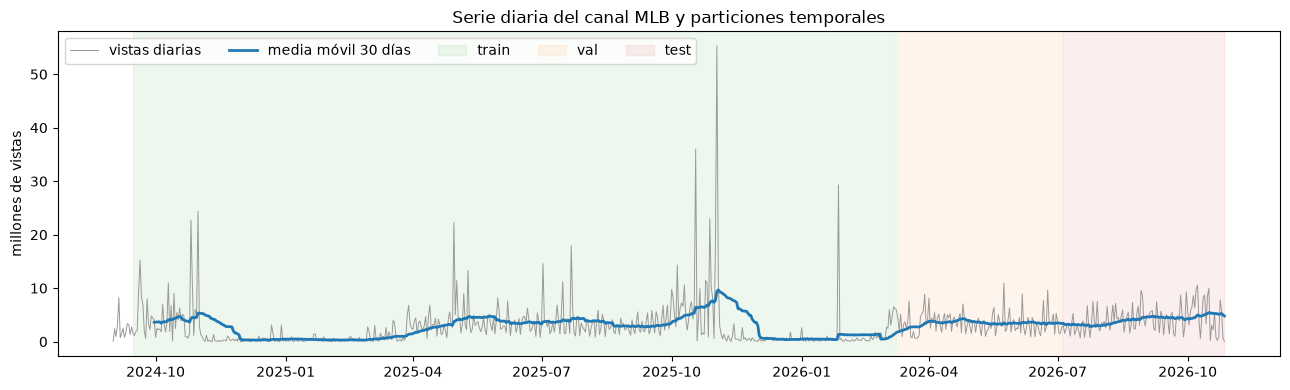

In [4]:
X, y, fechas = crear_ventanas_tabulares(daily, lookback=LOOKBACK)
part = particionar_serie(X, y, fechas)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values / 1e6, lw=0.7, color="0.6", label="vistas diarias")
ax.plot(daily.index, daily.rolling(30).mean() / 1e6, lw=2, color="C0", label="media móvil 30 días")
colores = {"train": "C2", "val": "C1", "test": "C3"}
for nombre, color in colores.items():
    f = part[f"dates_{nombre}"]
    ax.axvspan(f.min(), f.max(), color=color, alpha=0.08, label=nombre)
ax.set(title="Serie diaria del canal MLB y particiones temporales", ylabel="millones de vistas")
ax.legend(ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

**Interpretación.** La serie es muy ruidosa (días de partidos importantes o *highlights* virales generan picos de decenas de millones) y tiene asimetría a la derecha: la media está por encima de la mediana. Al final de la serie se observa una caída: los videos más recientes han tenido menos tiempo para acumular vistas, porque la API entrega una **instantánea** del conteo acumulado, no el tráfico histórico. Este efecto afecta sobre todo a la partición de test y se analiza en la sección 6.

## 2. Features, target y particiones

In [5]:
resumen = pd.DataFrame({
    n: {
        "filas": len(part[f"X_{n}"]),
        "desde": part[f"dates_{n}"].min().date(),
        "hasta": part[f"dates_{n}"].max().date(),
        "media_target": part[f"y_{n}"].mean(),
        "mediana_target": part[f"y_{n}"].median(),
    }
    for n in ["train", "val", "test"]
}).T
display(resumen)
display(X.assign(target_views=y, fecha_target=fechas).head(3))

,filas,desde,hasta,media_target,mediana_target
train,541,2024-09-15,2026-03-09,"2,657,255.06","1,339,242.00"
val,116,2026-03-10,2026-07-03,"3,504,676.33","3,414,320.00"
test,116,2026-07-04,2026-10-27,"4,162,828.52","3,812,638.00"


,lag_14,lag_13,lag_12,lag_11,lag_10,lag_9,lag_8,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1,target_views,fecha_target
0,"40,006.00","2,421,372.00","938,650.00","3,104,815.00","8,221,503.00","749,025.00","1,510,191.00","2,450,709.00","807,581.00","1,681,472.00","3,372,468.00","3,180,618.00","1,321,386.00","2,762,758.00","1,506,727.00",2024-09-15
1,"2,421,372.00","938,650.00","3,104,815.00","8,221,503.00","749,025.00","1,510,191.00","2,450,709.00","807,581.00","1,681,472.00","3,372,468.00","3,180,618.00","1,321,386.00","2,762,758.00","1,506,727.00","1,130,856.00",2024-09-16
2,"938,650.00","3,104,815.00","8,221,503.00","749,025.00","1,510,191.00","2,450,709.00","807,581.00","1,681,472.00","3,372,468.00","3,180,618.00","1,321,386.00","2,762,758.00","1,506,727.00","1,130,856.00","1,843,983.00",2024-09-17


In [6]:
# Comprobaciones de no fuga temporal
assert part["dates_train"].max() < part["dates_val"].min() < part["dates_test"].min()
# Cada fila usa únicamente días anteriores a su fecha objetivo
fila = 0
ventana = daily.loc[:fechas[fila]].iloc[-(LOOKBACK + 1):-1].values
assert np.allclose(ventana, X.iloc[fila].values) and daily.loc[fechas[fila]] == y.iloc[fila]
print("Particiones ordenadas en el tiempo y ventanas sin información del día objetivo: OK")

Particiones ordenadas en el tiempo y ventanas sin información del día objetivo: OK


- **Target:** `target_views` en el día *t*. Se usa en escala original para que el RMSE esté en vistas y sea interpretable por el usuario.
- **Features:** solo información disponible antes de *t* (14 lags). No se usan likes ni comentarios del mismo día para evitar fuga de información.
- **Particiones:** se respeta el orden temporal (no hay `shuffle`). Validación se usa **solo** para la función objetivo de Optuna; test se usa una sola vez, en el run `<familia>-final`.
- **Preprocesamiento:** `construir_pipeline()` encapsula `StandardScaler` + modelo. En HPO se ajusta con train; en el modelo final con train+validación. Test nunca participa en el ajuste, y el mismo pipeline serializado se usa en la API, así que el preprocesamiento es idéntico en entrenamiento e inferencia.

In [7]:
from src.entrenamiento.modelos import construir_pipeline, calcular_metricas, RANDOM_SEED
print("Semilla global:", RANDOM_SEED)
construir_pipeline("random-forest", {})

Semilla global: 42


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100


## 3. Baselines de referencia

Antes de comparar familias, se calculan tres pronósticos ingenuos sobre los mismos conjuntos. Un modelo solo aporta valor si mejora estos valores.

In [8]:
def baselines(Xp):
    return {
        "naive (lag_1)": Xp["lag_1"].values,
        "estacional semanal (lag_7)": Xp["lag_7"].values,
        "media 14 días": Xp.mean(axis=1).values,
    }

filas = []
for conjunto in ["val", "test"]:
    for nombre, pred in baselines(part[f"X_{conjunto}"]).items():
        m = calcular_metricas(part[f"y_{conjunto}"].values, pred)
        filas.append({"baseline": nombre, "conjunto": conjunto, **m})
df_base = pd.DataFrame(filas).pivot(index="baseline", columns="conjunto", values=["rmse", "mae"])
df_base

rmse                       mae             
conjunto                           test          val         test          val
baseline                                                                      
estacional semanal (lag_7) 2,730,831.41 2,531,934.80 1,909,141.58 1,820,919.56
media 14 días              2,453,313.77 2,084,892.54 1,904,698.23 1,562,349.41
naive (lag_1)              3,065,639.64 2,869,097.71 2,472,080.29 2,188,710.02

## 4. Espacios de búsqueda y presupuesto

El espacio de cada familia se define en `src/entrenamiento/hpo.py::sugerir_hiperparametros`:

| Familia | Hiperparámetro | Rango / valores | Escala |
|---|---|---|---|
| ridge | `alpha` | 1e-3 – 1000 | log |
| ridge | `solver` | auto, svd, cholesky, lsqr | categórica |
| random-forest | `n_estimators` | 50 – 250 (paso 50) | entera |
| random-forest | `max_depth` | 3 – 20 | entera |
| random-forest | `min_samples_split` | 2 – 10 | entera |
| random-forest | `min_samples_leaf` | 1 – 5 | entera |
| gradient-boosting | `learning_rate` | 0.01 – 0.3 | log |
| gradient-boosting | `max_iter` | 100 – 500 (paso 100) | entera |
| gradient-boosting | `max_depth` | 2 – 10 | entera |
| gradient-boosting | `max_leaf_nodes` | 15 – 63 | entera |
| gradient-boosting | `min_samples_leaf` | 5 – 50 | entera |
| gradient-boosting | `l2_regularization` | 1e-4 – 10 | log |

**Presupuesto:** 20 trials por familia (`n_trials` del flow), muestreo TPE con semilla 42 y dirección `minimize` sobre `val_rmse`. Cada trial es un child run `trial-NNN` del parent `hpo-<familia>` con sus hiperparámetros y métricas de validación.

In [9]:
import inspect
from src.entrenamiento import hpo
print(inspect.getsource(hpo.sugerir_hiperparametros))

def sugerir_hiperparametros(trial: optuna.Trial, familia: str) -> dict:
    if familia == "ridge":
        return {
            "alpha": trial.suggest_float("alpha", 1e-3, 1000.0, log=True),
            "solver": trial.suggest_categorical("solver", ["auto", "svd", "cholesky", "lsqr"]),
        }
    elif familia == "random-forest":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 20),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
        }
    elif familia == "gradient-boosting":
        return {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_iter": trial.suggest_int("max_iter", 100, 500, step=100),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "max_leaf_nodes": trial.suggest_int("max

## 5. Resultados del HPO (leídos de MLflow)

In [10]:
from src.entrenamiento.reportes import runs_ultima_ejecucion, columnas_params, tabla_comparacion

r = runs_ultima_ejecucion(cfg["experimento"])
padres, trials, finales = r["padres"], r["trials"], r["finales"]

display(padres[["tags.mlflow.runName", "params.n_trials", "params.metrica_objetivo", "params.direccion",
                "metrics.best_val_rmse", "start_time"]].rename(columns=lambda c: c.split(".")[-1]))
print("Trials registrados por familia:")
print(trials.groupby("tags.familia")["trial"].count().to_string())

,runName,n_trials,metrica_objetivo,direccion,best_val_rmse,start_time
65,hpo-ridge,20,val_rmse,minimize,"2,010,293.04",2026-10-27 01:23:17.476000+00:00
43,hpo-random-forest,20,val_rmse,minimize,"1,813,871.26",2026-10-27 01:23:25.668000+00:00
21,hpo-gradient-boosting,20,val_rmse,minimize,"1,934,964.12",2026-10-27 01:23:46.414000+00:00


Trials registrados por familia:
tags.familia
gradient-boosting    20
random-forest        20
ridge                20


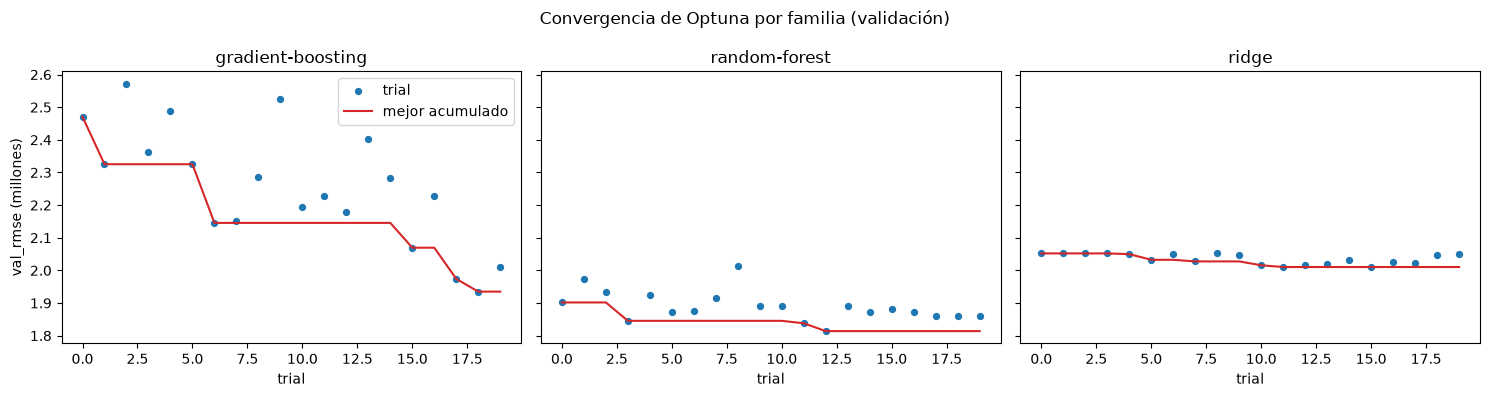

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (familia, t) in zip(axes, trials.groupby("tags.familia")):
    t = t.sort_values("trial")
    ax.scatter(t["trial"], t["metrics.val_rmse"] / 1e6, s=18, label="trial")
    ax.plot(t["trial"], t["metrics.val_rmse"].cummin() / 1e6, color="C3", label="mejor acumulado")
    ax.set(title=familia, xlabel="trial")
axes[0].set_ylabel("val_rmse (millones)")
axes[0].legend()
plt.suptitle("Convergencia de Optuna por familia (validación)")
plt.tight_layout(); plt.show()

In [12]:
for familia, t in trials.groupby("tags.familia"):
    cols = [c for c in columnas_params(t)]
    top = (t.sort_values("metrics.val_rmse")
             [["tags.mlflow.runName", *cols, "metrics.val_rmse", "metrics.val_mae"]]
             .head(5).rename(columns=lambda c: c.split(".")[-1]))
    display(Markdown(f"**{familia}** — 5 mejores de {len(t)} trials"))
    display(top)

**gradient-boosting** — 5 mejores de 20 trials

,runName,max_leaf_nodes,min_samples_leaf,max_iter,learning_rate,l2_regularization,max_depth,val_rmse,val_mae
2,trial-018,55,7,100,0.01443734657496408,0.084163591381892,8,"1,934,964.12","1,443,464.49"
3,trial-017,52,10,100,0.014973193250884247,0.02550794012778226,8,"1,973,755.93","1,494,783.00"
1,trial-019,61,19,100,0.021088143503439072,0.8149771745582733,9,"2,009,378.24","1,567,305.73"
5,trial-015,48,14,200,0.014556274036178518,0.10594972395821038,8,"2,069,480.66","1,682,165.90"
14,trial-006,36,10,100,0.028180680291847244,0.029914693021302164,8,"2,145,491.12","1,641,903.56"


**random-forest** — 5 mejores de 20 trials

,runName,min_samples_leaf,max_depth,min_samples_split,n_estimators,val_rmse,val_mae
30,trial-012,1,8,2,250,"1,813,871.26","1,373,437.93"
31,trial-011,1,7,3,250,"1,837,897.47","1,398,240.86"
39,trial-003,1,6,3,250,"1,845,388.93","1,407,028.14"
23,trial-019,2,8,4,250,"1,858,687.94","1,411,587.58"
25,trial-017,1,14,2,150,"1,858,938.80","1,409,511.19"


**ridge** — 5 mejores de 20 trials

,runName,alpha,solver,val_rmse,val_mae
53,trial-011,417.9950770779908,auto,"2,010,293.04","1,484,139.08"
49,trial-015,480.586158425876,lsqr,"2,011,539.74","1,486,796.48"
52,trial-012,620.4313258232027,auto,"2,015,225.98","1,491,582.47"
54,trial-010,635.4776228664264,auto,"2,015,662.99","1,492,016.00"
51,trial-013,107.23198976793843,svd,"2,020,684.54","1,478,780.05"


**Interpretación del HPO.**
- **ridge:** el error casi no depende del `solver`; el `alpha` óptimo es alto, señal de que conviene regularizar fuertemente lags muy correlacionados entre sí. Las diferencias entre trials son pequeñas: el modelo lineal tiene poca capacidad para el ruido de la serie.
- **random-forest:** los mejores trials usan profundidades intermedias; árboles muy profundos sobreajustan los picos virales del entrenamiento.
- **gradient-boosting:** los mejores trials combinan `learning_rate` bajos (≈0.015) con pocas iteraciones (100) y árboles de profundidad ~8; con tasas altas el error de validación sube rápidamente porque el modelo memoriza los picos.
- **Presupuesto:** ridge y random-forest alcanzan su mejor valor a mitad de la búsqueda (trials 11–12) y luego solo hay mejoras marginales. Gradient boosting, con el espacio más grande (6 hiperparámetros), todavía mejoraba cerca del final (trial 18): es la familia que más se beneficiaría de aumentar `n_trials`.

## 6. Comparación final de los mejores modelos

In [13]:
comp = tabla_comparacion(finales)
mejor_base = df_base[("rmse", "test")].idxmin()
fila_base = {"familia": f"baseline: {mejor_base}", "run": "-",
             "val_rmse": df_base.loc[mejor_base, ("rmse", "val")],
             "test_rmse": df_base.loc[mejor_base, ("rmse", "test")],
             "test_mae": df_base.loc[mejor_base, ("mae", "test")]}
tabla = pd.concat([comp.drop(columns="run_id"), pd.DataFrame([fila_base])], ignore_index=True)
tabla

,familia,run,val_rmse,test_rmse,test_mae,test_mape,mejores_params
0,random-forest,random-forest-final,"1,813,871.26","2,168,829.41","1,621,174.87",160.10,"{'min_samples_leaf': '1', 'max_depth': '8', 'min_samples_split': '2', 'n_estimators': '250'}"
1,gradient-boosting,gradient-boosting-final,"1,934,964.12","2,257,517.10","1,675,973.32",125.60,"{'max_leaf_nodes': '55', 'min_samples_leaf': '7', 'max_iter': '100', 'learning_rate': '0.01443734657496408', 'l2_reg..."
2,ridge,ridge-final,"2,010,293.04","2,318,929.81","1,763,913.74",143.32,"{'alpha': '417.9950770779908', 'solver': 'auto'}"
3,baseline: media 14 días,-,"2,084,892.54","2,453,313.77","1,904,698.23",NaN,NaN


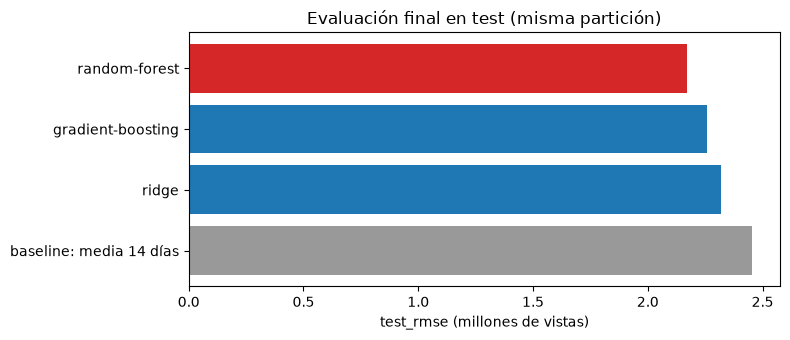

**Modelo seleccionado:** `random-forest` con test_rmse = 2,168,829 y test_mae = 1,621,175 vistas, 11.6% menos RMSE que el mejor baseline (`media 14 días`). Mejores hiperparámetros: `{'min_samples_leaf': '1', 'max_depth': '8', 'min_samples_split': '2', 'n_estimators': '250'}`.

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(tabla["familia"], tabla["test_rmse"] / 1e6, color=["C3"] + ["C0"] * (len(tabla) - 2) + ["0.6"])
ax.invert_yaxis()
ax.set(xlabel="test_rmse (millones de vistas)", title="Evaluación final en test (misma partición)")
plt.tight_layout(); plt.show()

ganador = comp.iloc[0]
mejora = 1 - ganador["test_rmse"] / fila_base["test_rmse"]
display(Markdown(
    f"**Modelo seleccionado:** `{ganador['familia']}` con test_rmse = {ganador['test_rmse']:,.0f} "
    f"y test_mae = {ganador['test_mae']:,.0f} vistas, {mejora:.1%} menos RMSE que el mejor baseline "
    f"(`{mejor_base}`). Mejores hiperparámetros: `{ganador['mejores_params']}`."
))

**Justificación de la selección.** Las tres familias se evaluaron con la misma partición, la misma métrica y el mismo presupuesto, así que la comparación es justa. El criterio es el menor `test_rmse` del run `<familia>-final`. El flow aplica esa regla automáticamente (`task_comparar_modelos`), sin fijar de antemano qué familia debe ganar. Los modelos de árboles capturan mejor las relaciones no lineales entre lags (por ejemplo, el efecto de un pico aislado) que el modelo lineal. El orden en validación y en test coincide, lo que indica que la selección no depende de un solo conjunto.

El MAPE es alto y poco informativo: se infla en los días con pocas vistas (denominador pequeño), por eso no es la métrica principal.

## 7. Diagnóstico del modelo seleccionado

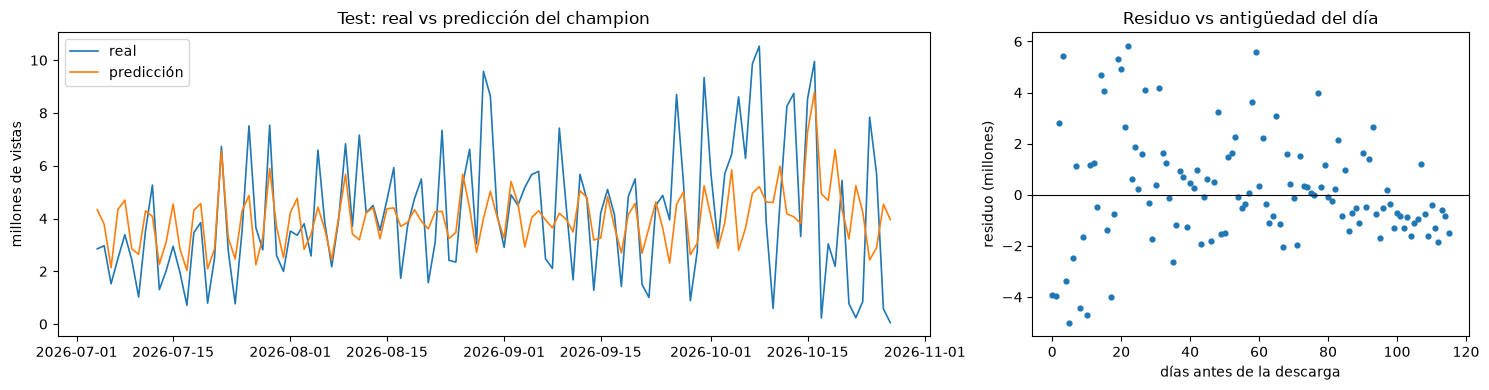

Residuo medio últimos 14 días: -1,302,934 | resto del test: 355,559


In [15]:
import mlflow
modelo = mlflow.sklearn.load_model(f"models:/{cfg['modelo']}@{cfg['alias']}")
pred_test = modelo.predict(part["X_test"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(part["dates_test"], part["y_test"] / 1e6, label="real", lw=1.2)
axes[0].plot(part["dates_test"], pred_test / 1e6, label="predicción", lw=1.2)
axes[0].set(title="Test: real vs predicción del champion", ylabel="millones de vistas"); axes[0].legend()

residuo = part["y_test"].values - pred_test
dias_desde = (daily.index.max() - part["dates_test"]).days
axes[1].scatter(dias_desde, residuo / 1e6, s=12)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Residuo vs antigüedad del día", xlabel="días antes de la descarga", ylabel="residuo (millones)")
plt.tight_layout(); plt.show()

ultimos = dias_desde < 14
print(f"Residuo medio últimos 14 días: {residuo[ultimos].mean():,.0f} | resto del test: {residuo[~ultimos].mean():,.0f}")

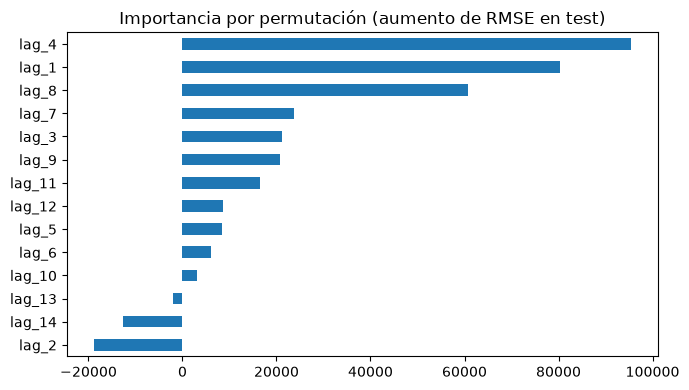

In [16]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(modelo, part["X_test"], part["y_test"], n_repeats=10, random_state=42,
                             scoring="neg_root_mean_squared_error")
imp_df = pd.Series(imp.importances_mean, index=part["X_test"].columns).sort_values()
imp_df.plot.barh(figsize=(7, 4), title="Importancia por permutación (aumento de RMSE en test)")
plt.tight_layout(); plt.show()

**Interpretación y limitaciones.**
- El modelo sigue el nivel y la tendencia de la serie, pero suaviza los picos extremos: ningún lag anticipa un evento viral, así que esos días concentran el error.
- La importancia por permutación se reparte entre varios lags (el más importante aumenta el RMSE menos de 5 % al permutarse). El modelo usa sobre todo el **nivel reciente** de la serie y no depende de un único rezago, lo que es coherente con que la media de 14 días sea el mejor baseline.
- **Efecto instantánea:** en los últimos días del test el residuo es negativo (el modelo sobreestima), porque esos videos aún no acumulan sus vistas finales. El error real en días “maduros” es menor que el RMSE global.
- La serie mezcla temporada regular, *postseason* y *offseason*; con solo ~2 años de historia, la generalización a otra temporada es incierta.
- La selección del champion usa test; un esquema de validación cruzada temporal (*walk-forward*) daría una estimación más robusta y es el siguiente paso.

Siguiente: [04-seleccion-registro](04-seleccion-registro.ipynb).